# Model Evaluation & Interpretability

In [1]:
import sys
sys.path.append('..')

import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, auc

from src.config import DATA_DIR, CHECKPOINT_PATH, FIGURES_DIR, CLASS_NAMES
from src.dataset import get_dataloaders, ChestXRayDataset, get_transforms, load_image_paths_and_labels
from src.model import create_model, get_device
from src.predict import load_model
from src.evaluate import evaluate_model, predict_proba, get_predictions_with_paths
from src.gradcam import plot_gradcam_grid

device = get_device()
print(f"Device: {device}")

Device: mps


## 1. Load Model

In [2]:
# Load trained model
model = create_model(pretrained=False, freeze_backbone=False, device=device)
model = load_model(model, CHECKPOINT_PATH, device)

checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)
print(f"Loaded model from epoch {checkpoint['epoch']}")
print(f"Val loss: {checkpoint['val_loss']:.4f}")

Loaded model from epoch 15
Val loss: 0.0176


## 2. Test Set Evaluation

In [3]:
# Get test loader
_, _, test_loader = get_dataloaders(DATA_DIR)

# Evaluate
metrics = evaluate_model(model, test_loader, device)

Train: 4433 images
Val:   783 images
Test:  624 images
EVALUATION RESULTS
Accuracy:  0.9054
Precision: 0.8805
Recall:    0.9821
F1 Score:  0.9285
ROC-AUC:   0.9783

Confusion Matrix:
      NORMAL  PNEUMONIA
      NORMAL        182         52
   PNEUMONIA          7        383

Classification Report:
              precision    recall  f1-score   support

      NORMAL       0.96      0.78      0.86       234
   PNEUMONIA       0.88      0.98      0.93       390

    accuracy                           0.91       624
   macro avg       0.92      0.88      0.89       624
weighted avg       0.91      0.91      0.90       624



## 3. Confusion Matrix

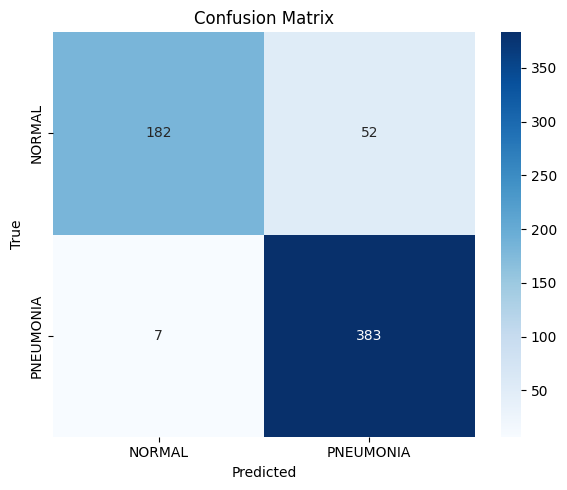

In [4]:
plt.figure(figsize=(6, 5))
sns.heatmap(
    metrics['confusion_matrix'],
    annot=True, fmt='d', cmap='Blues',
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'confusion_matrix.png', dpi=150)
plt.show()

## 4. ROC Curve

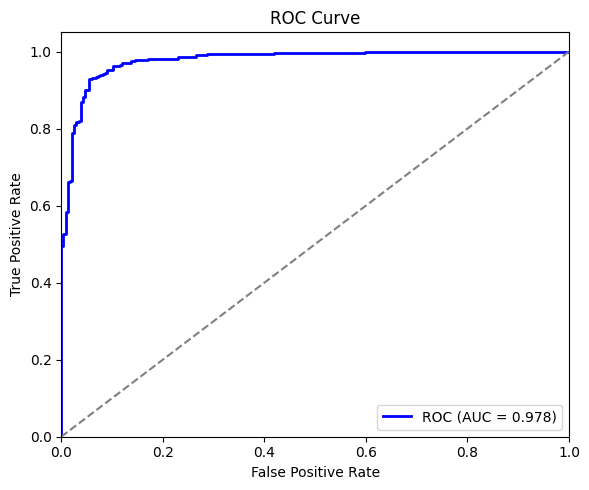

In [5]:
# Get predictions
probs, preds, labels = predict_proba(model, test_loader, device)

# ROC curve
fpr, tpr, _ = roc_curve(labels, probs)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'roc_curve.png', dpi=150)
plt.show()

## 5. Threshold Optimization

Default threshold is 0.5, but optimal threshold depends on the goal:
- **Max F1**: Balance precision and recall
- **Max Recall**: Catch all pneumonia cases (critical for medical)

In [6]:
from sklearn.metrics import precision_recall_curve, f1_score, precision_score, recall_score

# Get precision-recall curve
precision_curve, recall_curve, thresholds_pr = precision_recall_curve(labels, probs)

# Calculate F1 for each threshold
f1_scores = 2 * (precision_curve[:-1] * recall_curve[:-1]) / (precision_curve[:-1] + recall_curve[:-1] + 1e-8)

# Find optimal thresholds
best_f1_idx = np.argmax(f1_scores)
best_f1_threshold = thresholds_pr[best_f1_idx]

# Find threshold for 95% recall (medical requirement)
recall_target = 0.95
high_recall_idx = np.where(recall_curve[:-1] >= recall_target)[0]
if len(high_recall_idx) > 0:
    # Get the threshold with highest precision while maintaining recall >= 95%
    best_idx = high_recall_idx[np.argmax(precision_curve[:-1][high_recall_idx])]
    high_recall_threshold = thresholds_pr[best_idx]
else:
    high_recall_threshold = 0.5

print("=" * 50)
print("THRESHOLD OPTIMIZATION RESULTS")
print("=" * 50)
print(f"\nDefault threshold: 0.50")
print(f"  → F1: {f1_scores[np.argmin(np.abs(thresholds_pr - 0.5))]:.4f}")
print(f"\nOptimal for Max F1: {best_f1_threshold:.2f}")
print(f"  → F1: {f1_scores[best_f1_idx]:.4f}")
print(f"\nOptimal for ≥95% Recall: {high_recall_threshold:.2f}")
print(f"  → Recall: {recall_curve[:-1][best_idx]:.4f}")
print(f"  → Precision: {precision_curve[:-1][best_idx]:.4f}")

THRESHOLD OPTIMIZATION RESULTS

Default threshold: 0.50
  → F1: 0.9285

Optimal for Max F1: 0.89
  → F1: 0.9506

Optimal for ≥95% Recall: 0.91
  → Recall: 0.9513
  → Precision: 0.9464


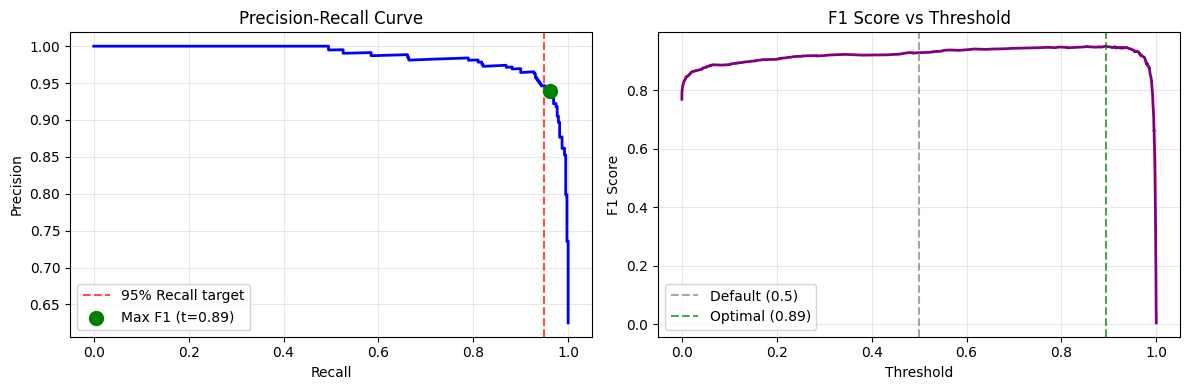


Recommendation: Use threshold 0.89 for balanced performance


In [7]:
# Plot Precision-Recall tradeoff
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Precision-Recall Curve
axes[0].plot(recall_curve, precision_curve, color='blue', lw=2)
axes[0].axvline(x=0.95, color='red', linestyle='--', alpha=0.7, label='95% Recall target')
axes[0].scatter([recall_curve[:-1][best_f1_idx]], [precision_curve[:-1][best_f1_idx]], 
                color='green', s=100, zorder=5, label=f'Max F1 (t={best_f1_threshold:.2f})')
axes[0].set_xlabel('Recall')
axes[0].set_ylabel('Precision')
axes[0].set_title('Precision-Recall Curve')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# F1 vs Threshold
axes[1].plot(thresholds_pr, f1_scores, color='purple', lw=2)
axes[1].axvline(x=0.5, color='gray', linestyle='--', alpha=0.7, label='Default (0.5)')
axes[1].axvline(x=best_f1_threshold, color='green', linestyle='--', alpha=0.7, label=f'Optimal ({best_f1_threshold:.2f})')
axes[1].set_xlabel('Threshold')
axes[1].set_ylabel('F1 Score')
axes[1].set_title('F1 Score vs Threshold')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'threshold_optimization.png', dpi=150)
plt.show()

print(f"\nRecommendation: Use threshold {best_f1_threshold:.2f} for balanced performance")

## 6. Grad-CAM Visualizations

In [8]:
# Get test dataset with paths
test_paths, test_labels = load_image_paths_and_labels(DATA_DIR, 'test')
test_dataset = ChestXRayDataset(test_paths, test_labels, transform=get_transforms(False))

# Get predictions with paths
results = get_predictions_with_paths(model, test_dataset, device)

# Separate correct and incorrect
correct = [r for r in results if r['correct']]
incorrect = [r for r in results if not r['correct']]

print(f"Correct: {len(correct)}, Incorrect: {len(incorrect)}")

Correct: 565, Incorrect: 59


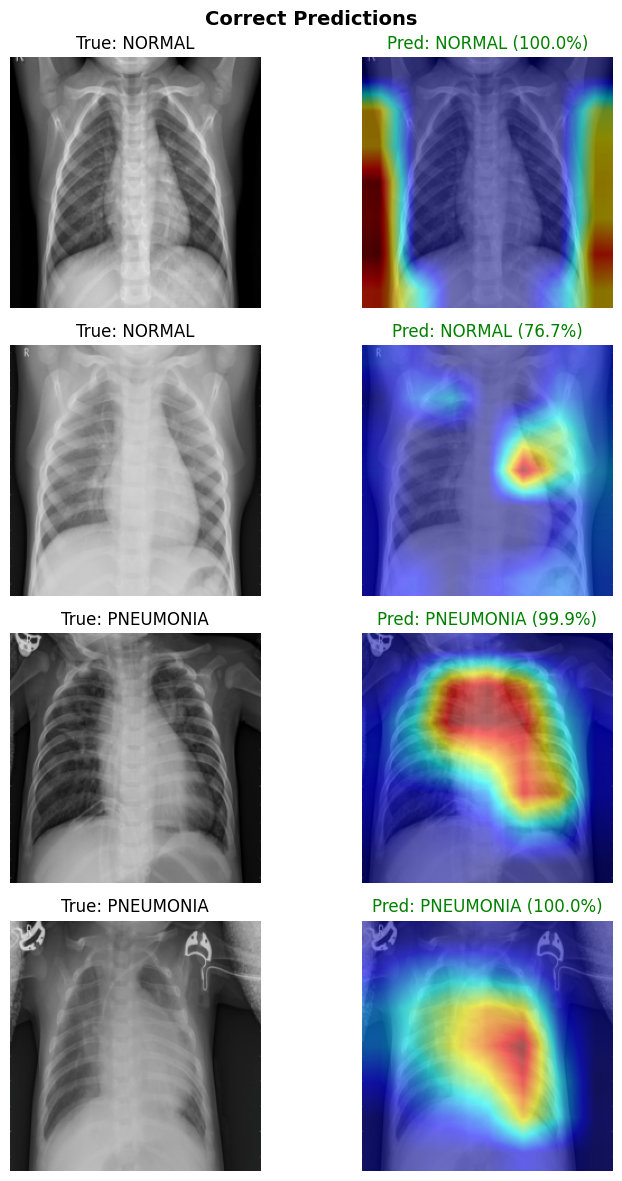

In [9]:
# Grad-CAM for correct predictions
import random
random.seed(42)

sample_correct = random.sample(correct, min(4, len(correct)))
paths = [r['path'] for r in sample_correct]
labels = [CLASS_NAMES[r['true_label']] for r in sample_correct]

plot_gradcam_grid(
    model, paths, labels, device,
    save_path=str(FIGURES_DIR / 'gradcam_correct.png'),
    title='Correct Predictions'
)

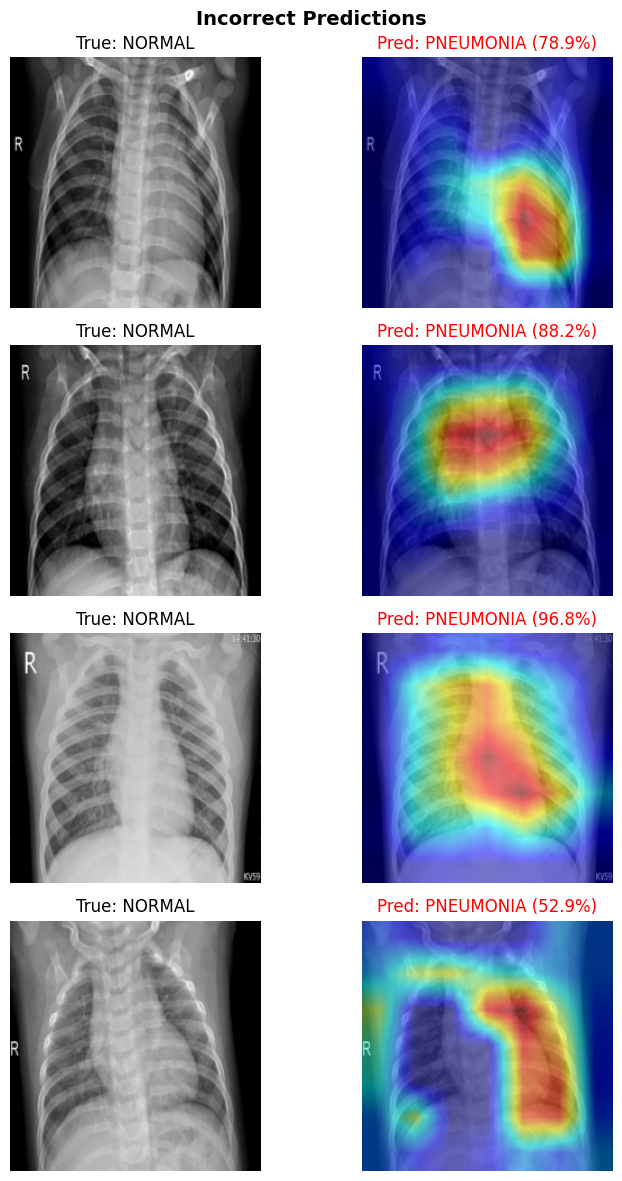

In [10]:
# Grad-CAM for incorrect predictions (if any)
if incorrect:
    sample_incorrect = random.sample(incorrect, min(4, len(incorrect)))
    paths = [r['path'] for r in sample_incorrect]
    labels = [CLASS_NAMES[r['true_label']] for r in sample_incorrect]

    plot_gradcam_grid(
        model, paths, labels, device,
        save_path=str(FIGURES_DIR / 'gradcam_incorrect.png'),
        title='Incorrect Predictions'
    )
else:
    print("No incorrect predictions!")

## 7. Summary

In [11]:
print("=" * 50)
print("FINAL RESULTS")
print("=" * 50)
print(f"Accuracy:  {metrics['accuracy']:.1%}")
print(f"Precision: {metrics['precision']:.1%}")
print(f"Recall:    {metrics['recall']:.1%} (Pneumonia detection rate)")
print(f"F1 Score:  {metrics['f1']:.1%}")
print(f"ROC-AUC:   {metrics['roc_auc']:.3f}")
print("\nFigures saved to outputs/figures/")

FINAL RESULTS
Accuracy:  90.5%
Precision: 88.0%
Recall:    98.2% (Pneumonia detection rate)
F1 Score:  92.8%
ROC-AUC:   0.978

Figures saved to outputs/figures/


**Next:** Phase 7 - API Development